
# Multi-Period MPC Portfolio Optimizer — Scaffold

**Steps 1 and 2** of a general model-predictive-control (MPC) portfolio optimizer, built as a
research scaffold on top of the same data/artifacts as `optimal_portfolio.ipynb`.

## What this is

The single-period MVO in `optimal_portfolio.ipynb` **liquidates to flat at every close**: each
trading day is an independent QP. This notebook replaces that with a **receding-horizon MPC**
on a **30-minute period grid** that explicitly **carries inventory across periods AND across
the close/overnight boundary**.

At each decision period *k* the optimizer:

1. Assembles the next `HORIZON` periods' alpha `A`, per-period covariance $\Sigma_\tau$, and
   costs.
2. Solves a horizon trajectory QP over dollar-holdings $H_\text{hold}\in\mathbb{R}^{N\times H}$
   and dollar-trades $U\in\mathbb{R}^{N\times H}$, subject to inventory dynamics
   $H_\tau=H_{\tau-1}+U_\tau$ and hard no-trade constraints on non-tradeable periods.
3. **Executes only the first trade $u_k=U[:,0]$**, advances realized state $h\leftarrow h+u_k$,
   marks PnL over the actual period return, and re-solves at period *k+1*.

## Period clock (heterogeneous periods)

Two kinds of periods:

- **Intraday tradeable**: thirteen 30-min intervals per day
  (`9:30→10:00, 10:00→10:30, ... 15:30→16:00`).
- **Overnight non-tradeable**: one interval per trading day
  (`16:00 → next 9:30`), with `U=0` forced.

Each period carries: `duration_hours`, `tradeable: bool`, per-period covariance $\Sigma_\tau$,
per-period alpha $a_\tau$, per-period spread rate, per-period impact coefficient.

## Objective (maximize, per horizon call)

$$
\sum_{\tau=0}^{H-1}\!\Big[a_\tau^{\top}h_\tau
 - \tfrac{\lambda}{2}\,s_\tau\,h_\tau^{\top}\Sigma_R h_\tau
 - \text{spread}_\tau^{\top}|U_\tau|
 - \gamma\,\sum_i c_{i,\tau}\,|U_{i,\tau}|^{3/2}\Big]
 \;-\; \underbrace{\tfrac{\lambda_T}{2}h_{H-1}^{\top}\Sigma_R h_{H-1}
 + \gamma\,\sum_i c_{i,H-1}\,|h_{i,H-1}|^{3/2}}_{\Phi_\text{terminal}}
$$

- $s_\tau$ = per-period covariance scale (intraday: $1/N_\text{intra}$; overnight: 1).
- $c_{i,\tau} = \sigma_i / \sqrt{\text{ADV}\$_i}$ evaluated on the trading day of period $\tau$.
  Same square-root/Almgren-form impact coefficient the single-period notebook uses.
- $\gamma$ is a **scalar** shared across names (`IMPACT_GAMMA = 0.5`).
- $\lambda$ risk-aversion, 2-factor neutrality, and a per-period ex-ante vol cap on tradeable
  periods (same `sqrtm`-based reformulation as the single-period optimizer).

## What is real vs. a scaffold placeholder

Real (production-quality) pieces:

- Data (`imbalance`/`tbbo`/`statistics` from the Databento parquet cache — already materialized).
- 30-min mid marks + open/close auction marks, and the derived per-period return matrix.
- Loaded artifacts: factor covariance ($L, \Sigma_f, \varepsilon_\text{diag}, \Sigma_R$) and
  the fitted close-auction forecast pipeline.
- **Square-root impact** in objective (`cp.power(cp.abs(U), 1.5)`) and PnL accounting, with a
  **per-(name, intraday-bucket) causal coefficient** `sigma_i / sqrt(PV$_{i, b, d})` — where
  `PV$_{i, b, d}` is the EWMA of PRIOR DAYS' per-bucket dollar volume for `(name i, bucket b)`,
  shifted 1 day. This naturally gives an intraday U-shape (open/close buckets have larger
  `PV$` → smaller coefficient → lower impact; thin midday buckets → higher impact). Same
  "never free to trade" max-fallback as `ImpactModel.get_impact_coeff`.
- The MPC QP itself: compiled once with `cvxpy` Parameters, warm-solved with `cp.CLARABEL`
  (`cp.power(..., 1.5)` is a power-cone atom `CLARABEL` handles natively).
- The sequential (non-parallel) MPC loop that carries realized inventory across periods.

Scaffold placeholders (each flagged inline):

- **Per-period covariance $\Sigma_\tau$**: uniform intraday split `SIGMA_R / N_INTRADAY` plus a
  fixed overnight multiplier — a real design needs an intraday U-shape and a separate
  overnight-gap covariance.
- **Per-period vol reused from daily**: `sigma_i` in the impact coefficient is still the
  causal EWMA daily-return vol (the existing `vol` column). Per-period `PV$` is per-bucket,
  so the U-shape falls out of that. A per-period causal vol would be a fuller U-shape — noted
  as a future refinement, not built here.
- **Terminal cost-to-go $\Phi_\text{terminal}$**: terminal risk + notional 3/2-power
  liquidation impact. Placeholder for a proper Gârleanu–Pedersen value function.
- **Single alpha source**: only the close-auction forecast is wired in (spike on the last
  intraday period of each day). No `AlphaAggregator` term-structure yet.
- **Spread cost**: per-name **average** quoted spread over the sample, held constant across
  periods.
- **Impact is temporary only**: no permanent-impact term.


In [1]:

# --- Imports & environment -----------------------------------------------
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import cvxpy as cp
import scipy.linalg
import joblib
from datetime import time as dtime

load_dotenv()
pl.enable_string_cache()

# Notebook lives in optimizer/. Cache path mirrors optimal_portfolio.ipynb.
CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)
print(f"CACHE_DIR: {CACHE_DIR}")

with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
with open("../top_100_universe.txt", "r") as f:
    ACTIVE_SET = [line.strip() for line in f]

N = len(ACTIVE_SET)
SYM_IDX = {s: i for i, s in enumerate(ACTIVE_SET)}
START = "2025-06-11"
END = "2026-06-11"
DATASET = "XNAS.ITCH"
print(f"N = {N} active names, sample window [{START}, {END})")


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
N = 100 active names, sample window [2025-06-11, 2026-06-11)


## Data — pull cached parquet layers only


In [2]:

# --- Cached data scans (parquet layer only) ------------------------------
# adapter.scan_data raises FileNotFoundError if the parquet isn't present -- we NEVER
# trigger a Databento download from this notebook. The three schemas below are already
# materialized by optimal_portfolio.ipynb / forecast/forecasting.ipynb for this window.

df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE, start_date=START, end_date=END,
        dataset=DATASET, schema="imbalance",
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty", "paired_qty", "ref_price"])
    .with_columns(
        pl.col("ts_event").dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical),
    )
    .filter(
        pl.col("ts_event").dt.time().is_between(pl.time(9, 30), pl.time(16, 0)),
        pl.col("symbol").is_in(ACTIVE_SET),
    )
)

df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE, start_date=START, end_date=END,
        dataset=DATASET, schema="tbbo",
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .filter(
        pl.col("ts_event").dt.time().is_between(pl.time(13, 30), pl.time(21, 0)),
        pl.col("symbol").is_in(ACTIVE_SET),
    )
    .with_columns(pl.col("ts_event").dt.convert_time_zone("America/New_York"))
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(9, 30), pl.time(16, 0)))
    .with_columns(pl.col("symbol").cast(pl.Categorical))
)

df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE, start_date=START, end_date=END,
        dataset=DATASET, schema="statistics",
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col("ts_event").dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical),
    )
    .filter(pl.col("symbol").is_in(ACTIVE_SET))
)
print("scans built (lazy)")


[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet
[GenericAdapter] scan_parquet: 6436dd54a7ced32262a3242e08d42d20.parquet
[GenericAdapter] scan_parquet: 83ab27f48711d5689292fe953cab702b.parquet
scans built (lazy)



### Close-auction alpha features + causal daily ADV / vol

Reused verbatim from `optimal_portfolio.ipynb` cells 2-4. Two pieces we need:

- `features_df`: per-day per-name features feeding `forecast_pipe.joblib`.
- `daily_vol` and `avg_daily_dollar_volume`: causal EWMA daily-return vol and daily $-volume,
  BOTH shifted 1 day — same construction as the single-period optimizer's `ImpactModel`.


In [3]:

# --- Feature engineering + causal daily vol & ADV -----------------------
avg_daily_dollar_volume = (
    df_trades
    .select(["ts_event", "symbol", "price", "size"])
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"])
    .agg((pl.col("size") * pl.col("price")).sum().alias("day_volume"))
    .sort(["date", "symbol"])
    .with_columns(
        pl.col("day_volume").ewm_mean(span=10, adjust=True).shift(1).over("symbol").alias("ADV"),
    )
    .drop("day_volume")
    .collect(engine="streaming")
)

# Causal per-(date, symbol) daily return vol: EWMA of squared daily returns, SHIFTED 1 day.
# Verbatim from optimal_portfolio.ipynb -- day close = last mid.
daily_vol = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"),
    )
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(pl.col("mid").last().alias("close"))
    .sort(["date", "symbol"])
    .with_columns(pl.col("close").pct_change().over("symbol").alias("day_ret"))
    .with_columns(
        pl.col("day_ret").pow(2).ewm_mean(span=10, adjust=True).shift(1).over("symbol").sqrt().alias("vol"),
    )
    .select(["date", "symbol", "vol"])
    .collect(engine="streaming")
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"),
    )
    .with_columns(((pl.col("ask_px_00") - pl.col("bid_px_00")) / pl.col("mid")).alias("spread_return"))
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15, 49, 55), pl.time(15, 50, 0)))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(pl.col("mid").last(), pl.col("spread_return").mean())
    .rename({"mid": "entry_price"})
    .collect(engine="streaming")
)

recent_return = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"),
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15, 40, 0), pl.time(15, 49, 59)))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg((pl.col("mid").last() - pl.col("mid").first()) / pl.col("mid").first())
    .rename({"mid": "recent_return"})
    .collect(engine="streaming")
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15, 50, 0), pl.time(15, 50, 5)))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(pl.col(["ts_event", "side", "total_imbalance_qty", "paired_qty", "ref_price"]).first())
    .collect(engine="streaming")
)

features_df = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(avg_daily_dollar_volume, on=["date", "symbol"])
    .join(recent_return, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .with_columns(
        (pl.col("total_imbalance_qty") * pl.col("ref_price")).alias("dollar_imbalance"),
        (pl.col("paired_qty") * pl.col("ref_price")).alias("paired_dollars"),
        (pl.when(pl.col("side") == "B").then(1)
         .when(pl.col("side") == "A").then(-1)
         .when(pl.col("side") == "N").then(0)).alias("sign"),
    )
    .with_columns((pl.col("sign") * pl.col("dollar_imbalance")).alias("signed_dollar_imbalance"))
    .drop_nulls()
    .with_columns(
        (pl.col("paired_dollars") / pl.col("ADV")).alias("auction_dollar_volume_ratio"),
        (pl.when(pl.col("paired_dollars") != 0)
           .then(pl.col("signed_dollar_imbalance") / pl.col("paired_dollars"))
           .otherwise(0)).alias("net_signed_imb"),
    )
    .with_columns(
        (pl.col("recent_return") - pl.col("recent_return").mean().over("date")).alias("recent_return_xm"),
        (pl.col("auction_dollar_volume_ratio")
         - pl.col("auction_dollar_volume_ratio").mean().over("date")).alias("auction_dollar_volume_ratio_xm"),
        (((pl.col("net_signed_imb").rank().over(pl.col("date"))
           - pl.col("net_signed_imb").rank().min().over(pl.col("date")))
          / (pl.col("net_signed_imb").rank().max().over(pl.col("date"))
             - pl.col("net_signed_imb").rank().min().over(pl.col("date"))))
         * 2 - 1).alias("norm_rank_net_imb"),
    )
    .with_columns(
        (pl.col("norm_rank_net_imb") * pl.col("recent_return_xm")).alias("norm_rank_net_x_recent_xm"),
        (pl.col("auction_dollar_volume_ratio_xm") * pl.col("norm_rank_net_imb")).alias("norm_rank_net_x_auction"),
    )
)
print(f"features rows (full sample): {features_df.height:,}")


features rows (full sample): 17,849



## Period clock

Global sequence of periods over the sample. Each period is one row of `periods_df`:

| column          | meaning                                                              |
|-----------------|----------------------------------------------------------------------|
| `pidx`          | integer index in the global period sequence                          |
| `date`          | trading date (start-side of the period)                              |
| `start_ts`      | timezone-aware ET timestamp when the period begins (decision moment) |
| `end_ts`        | timezone-aware ET timestamp when the period ends (PnL mark)          |
| `duration_hr`   | float hours (`0.5` intraday; ~17.5 overnight)                        |
| `tradeable`     | `True` for intraday intervals, `False` for overnight                 |
| `kind`          | `"intraday"` / `"overnight"`                                         |
| `is_close_period` | `True` for the last intraday period each day (`15:30→16:00`)      |


In [4]:

# --- Global period index -------------------------------------------------
trading_days = (
    df_trades
    .select(pl.col("ts_event").dt.date().alias("date"))
    .unique()
    .sort("date")
    .collect(engine="streaming")["date"]
    .to_list()
)
print(f"trading days in cache: {len(trading_days)} "
      f"(first {trading_days[0]} .. last {trading_days[-1]})")

N_INTRADAY = 13   # 9:30->10:00, ..., 15:30->16:00 (thirteen 30-min buckets)

def _intraday_edges():
    edges = []
    t = dtime(9, 30)
    for _ in range(N_INTRADAY):
        e_min = (t.hour * 60 + t.minute + 30)
        e = dtime(e_min // 60, e_min % 60)
        edges.append((t, e))
        t = e
    return edges

INTRADAY_EDGES = _intraday_edges()
assert INTRADAY_EDGES[0]  == (dtime(9, 30), dtime(10, 0))
assert INTRADAY_EDGES[-1] == (dtime(15, 30), dtime(16, 0))

period_rows = []
for di, date in enumerate(trading_days):
    for j, (s, e) in enumerate(INTRADAY_EDGES):
        period_rows.append({
            "date": date, "start_time": s, "end_time": e,
            "kind": "intraday", "tradeable": True,
            "is_close_period": (j == N_INTRADAY - 1),
        })
    if di + 1 < len(trading_days):
        period_rows.append({
            "date": date, "start_time": dtime(16, 0), "end_time": dtime(9, 30),
            "kind": "overnight", "tradeable": False, "is_close_period": False,
        })

periods_df = pl.DataFrame(period_rows).with_row_index("pidx")

def _mk_ts(row_idx, which):
    r = periods_df.row(row_idx, named=True)
    if which == "start":
        d, t = r["date"], r["start_time"]
    else:
        d, t = r["date"], r["end_time"]
        if r["kind"] == "overnight":
            d = trading_days[trading_days.index(r["date"]) + 1]
    import datetime as _dt
    return _dt.datetime.combine(d, t)

start_naive = [_mk_ts(i, "start") for i in range(periods_df.height)]
end_naive   = [_mk_ts(i, "end")   for i in range(periods_df.height)]
periods_df = periods_df.with_columns(
    pl.Series("start_ts_naive", start_naive).dt.replace_time_zone("America/New_York").alias("start_ts"),
    pl.Series("end_ts_naive",   end_naive  ).dt.replace_time_zone("America/New_York").alias("end_ts"),
).with_columns(
    ((pl.col("end_ts") - pl.col("start_ts")).dt.total_seconds() / 3600.0).alias("duration_hr"),
).drop(["start_time", "end_time"])

P_total = periods_df.height
print(f"total periods: {P_total}  ({periods_df.filter(pl.col('tradeable')).height} tradeable, "
      f"{periods_df.filter(~pl.col('tradeable')).height} overnight)")
periods_df.head(20)


trading days in cache: 251 (first 2025-06-11 .. last 2026-06-10)
total periods: 3513  (3263 tradeable, 250 overnight)


pidx,date,kind,tradeable,is_close_period,start_ts,end_ts,duration_hr
u64,date,str,bool,bool,"datetime[μs, America/New_York]","datetime[μs, America/New_York]",f64
0,2025-06-11,"""intraday""",true,false,2025-06-11 09:30:00 EDT,2025-06-11 10:00:00 EDT,0.5
1,2025-06-11,"""intraday""",true,false,2025-06-11 10:00:00 EDT,2025-06-11 10:30:00 EDT,0.5
2,2025-06-11,"""intraday""",true,false,2025-06-11 10:30:00 EDT,2025-06-11 11:00:00 EDT,0.5
3,2025-06-11,"""intraday""",true,false,2025-06-11 11:00:00 EDT,2025-06-11 11:30:00 EDT,0.5
4,2025-06-11,"""intraday""",true,false,2025-06-11 11:30:00 EDT,2025-06-11 12:00:00 EDT,0.5
…,…,…,…,…,…,…,…
15,2025-06-12,"""intraday""",true,false,2025-06-12 10:00:00 EDT,2025-06-12 10:30:00 EDT,0.5
16,2025-06-12,"""intraday""",true,false,2025-06-12 10:30:00 EDT,2025-06-12 11:00:00 EDT,0.5
17,2025-06-12,"""intraday""",true,false,2025-06-12 11:00:00 EDT,2025-06-12 11:30:00 EDT,0.5



## Period marks and period returns

For each period boundary we need one mark price per name so that

$$r_\tau = \text{mark}_{\tau+1} / \text{mark}_\tau - 1.$$

- **Intraday boundaries (10:00, 10:30, ..., 15:30)**: last `mid = (ask_px_00 + bid_px_00)/2`
  in each 30-min bucket, from the tbbo tape.
- **Open auction (09:30)**: statistics `stat_type == 1` price when present; falls back to the
  first tbbo mid of the day.
- **Close auction (16:00)**: statistics `stat_type == 11` price (always present in this cache).


In [5]:

# --- Build mark price matrix per (period boundary, name) -----------------
tbbo_mids = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"),
        pl.col("ts_event").dt.hour().alias("h"),
        pl.col("ts_event").dt.minute().alias("m"),
    )
    .with_columns(((pl.col("h") * 60 + pl.col("m")) // 30 * 30).alias("bucket_min_start"))
    .group_by(["date", "symbol", "bucket_min_start"], maintain_order=True)
    .agg(pl.col("mid").last())
    .collect(engine="streaming")
)

auctions = (
    df_stats
    .filter(pl.col("stat_type").is_in([1, 11]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol", "stat_type"], maintain_order=True)
    .agg(pl.col("price").first().alias("px"))
    .collect(engine="streaming")
)
auc_open  = auctions.filter(pl.col("stat_type") == 1 ).drop("stat_type").rename({"px": "open_px"})
auc_close = auctions.filter(pl.col("stat_type") == 11).drop("stat_type").rename({"px": "close_px"})

def _boundaries():
    bs = []
    for d in trading_days:
        bs.append((d, 9 * 60 + 30))                                    # 09:30 open
        for j in range(1, N_INTRADAY):                                 # 10:00 .. 15:30
            bs.append((d, 9 * 60 + 30 + 30 * j))
        bs.append((d, 16 * 60))                                        # 16:00 close
    return bs

boundaries = _boundaries()
n_boundaries = len(boundaries)
b_idx = {b: i for i, b in enumerate(boundaries)}
print(f"n_boundaries: {n_boundaries}  (expected (N_INTRADAY+1) * n_days = "
      f"{(N_INTRADAY + 1) * len(trading_days)})")

M = np.full((n_boundaries, N), np.nan)

def _dates_as_date(polars_frame, col="date"):
    # Return the date column as a list of datetime.date objects (matches b_idx key type).
    return polars_frame[col].to_list()   # polars Date -> datetime.date natively

# 4a) 30-min bucket ends -> boundary at bucket_start + 30 minutes
_dates_m = _dates_as_date(tbbo_mids)
_syms_m  = [SYM_IDX.get(s, -1) for s in tbbo_mids["symbol"].to_list()]
_bmins_m = (tbbo_mids["bucket_min_start"].to_numpy() + 30).astype(int)
_mids_v  = tbbo_mids["mid"].to_numpy()
_bnd_m = np.array([b_idx.get((d, int(m)), -1) for d, m in zip(_dates_m, _bmins_m)])
_syms_m = np.array(_syms_m)
_mask = (_bnd_m >= 0) & (_syms_m >= 0) & np.isfinite(_mids_v)
M[_bnd_m[_mask], _syms_m[_mask]] = _mids_v[_mask]

# 4b) 09:30 open-auction price overwrites, then fallback to earliest tbbo mid.
_dates_o = _dates_as_date(auc_open)
_syms_o  = np.array([SYM_IDX.get(s, -1) for s in auc_open["symbol"].to_list()])
_opx     = auc_open["open_px"].to_numpy()
_bnd_o   = np.array([b_idx.get((d, 9 * 60 + 30), -1) for d in _dates_o])
_mask_o  = (_bnd_o >= 0) & (_syms_o >= 0) & np.isfinite(_opx)
M[_bnd_o[_mask_o], _syms_o[_mask_o]] = _opx[_mask_o]

first_mid = (
    tbbo_mids
    .sort(["symbol", "date", "bucket_min_start"])
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(pl.col("mid").first().alias("first_mid"))
)
_dates_f = _dates_as_date(first_mid)
_syms_f  = np.array([SYM_IDX.get(s, -1) for s in first_mid["symbol"].to_list()])
_fpx     = first_mid["first_mid"].to_numpy()
_bnd_f   = np.array([b_idx.get((d, 9 * 60 + 30), -1) for d in _dates_f])
for b_i, s_i, px in zip(_bnd_f, _syms_f, _fpx):
    if b_i >= 0 and s_i >= 0 and np.isnan(M[b_i, s_i]) and np.isfinite(px):
        M[b_i, s_i] = px

# 4c) 16:00 close-auction price overwrites.
_dates_c = _dates_as_date(auc_close)
_syms_c  = np.array([SYM_IDX.get(s, -1) for s in auc_close["symbol"].to_list()])
_cpx     = auc_close["close_px"].to_numpy()
_bnd_c   = np.array([b_idx.get((d, 16 * 60), -1) for d in _dates_c])
_mask_c  = (_bnd_c >= 0) & (_syms_c >= 0) & np.isfinite(_cpx)
M[_bnd_c[_mask_c], _syms_c[_mask_c]] = _cpx[_mask_c]

print(f"marks matrix M: shape {M.shape}, NaN fraction {np.isnan(M).mean():.3%}")


n_boundaries: 3514  (expected (N_INTRADAY+1) * n_days = 3514)
marks matrix M: shape (3514, 100), NaN fraction 86.429%


In [6]:

# --- Compute per-period return matrix R_period (P_total x N) ------------
R_period = np.zeros((P_total, N))
per_rows = periods_df.to_pandas()
for _, row in per_rows.iterrows():
    d0 = row["date"].date() if hasattr(row["date"], "date") else row["date"]
    if row["kind"] == "intraday":
        d1 = d0
        m0 = row["start_ts"].hour * 60 + row["start_ts"].minute
        m1 = row["end_ts"].hour   * 60 + row["end_ts"].minute
    else:
        d1 = row["end_ts"].date()
        m0 = 16 * 60
        m1 = 9 * 60 + 30
    b0 = b_idx.get((d0, m0))
    b1 = b_idx.get((d1, m1))
    if b0 is None or b1 is None:
        continue     # (defensive) leave R=0 -- happens only if a boundary is missing
    p0 = M[b0]; p1 = M[b1]
    with np.errstate(invalid="ignore", divide="ignore"):
        r = p1 / p0 - 1.0
    r = np.where(np.isfinite(r), r, 0.0)
    r = np.clip(r, -0.5, 0.5)     # cap absurd values from data pathologies
    R_period[int(row["pidx"])] = r

_intra = periods_df.filter(pl.col("kind") == "intraday")["pidx"].to_numpy()
_on    = periods_df.filter(pl.col("kind") == "overnight")["pidx"].to_numpy()
print(f"intraday |r| median: {np.median(np.abs(R_period[_intra])):.5f}, "
      f"overnight |r| median: {np.median(np.abs(R_period[_on])):.5f}")


intraday |r| median: 0.00000, overnight |r| median: 0.00461



## Alpha wiring (single alpha: close-auction)

Only the close-auction forecast is wired in for the scaffold. Placed as a spike on the last
intraday period of each day (`is_close_period`).

**Reveal-time simplification.** The imbalance print is at 15:50. Since our decision grid is
30-min, we simplify: at decision mark `k` = `15:30 on day d`, day *d*'s close-alpha is
available and placed at horizon slot `tau=0`; at earlier marks it is 0. This preserves the MPC
property that alphas *enter the horizon over time*. A real deployment would run the solve at
15:50 with a shorter close period. Flagged as **placeholder for a full `AlphaAggregator`
term-structure layer**.


In [7]:

# --- Per-day close-auction alpha vectors --------------------------------
FEATURES = [
    "norm_rank_net_imb",
    "recent_return_xm",
    "auction_dollar_volume_ratio_xm",
    "norm_rank_net_x_recent_xm",
    "norm_rank_net_x_auction",
]
forecast_pipe = joblib.load("../forecast/forecast_pipe.joblib")

alpha_by_date = {}
for grp, day_df in features_df.group_by("date"):
    date = grp[0] if isinstance(grp, tuple) else grp
    a = np.zeros(N)
    preds = forecast_pipe.predict(day_df[FEATURES].to_numpy()).ravel()
    for sym, p in zip(day_df["symbol"], preds):
        a[SYM_IDX[sym]] = float(p)
    alpha_by_date[date] = a
print(f"close-auction alpha vectors for {len(alpha_by_date)} days  "
      f"(mean |alpha| across days = "
      f"{np.mean([np.abs(v).mean() for v in alpha_by_date.values()]):.2e})")


close-auction alpha vectors for 247 days  (mean |alpha| across days = 4.39e-04)


In [8]:

# --- Alpha-matrix builder for MPC solves --------------------------------
# Use polars .to_list() so dates stay as datetime.date (matching alpha_by_date keys).
_date_of  = periods_df["date"].to_list()
_start_min = np.array([ts.hour * 60 + ts.minute for ts in periods_df["start_ts"].to_list()])
_is_close = periods_df["is_close_period"].to_numpy()

def build_alpha_horizon(k: int, H: int) -> np.ndarray:
    # A[:, tau] = close-alpha spike for future period k+tau iff it is a close period AND its
    # date d's alpha is revealed by time period k. Reveal rule: alpha of date d is available
    # once the current period is on date d at or after the 15:30 mark.
    A = np.zeros((N, H))
    if k >= P_total:
        return A
    current_date = _date_of[k]
    current_min  = _start_min[k]
    reveal_days = set()
    if current_min >= 15 * 60 + 30:
        reveal_days.add(current_date)
    for tau in range(H):
        p = k + tau
        if p >= P_total:
            break
        if not _is_close[p]:
            continue
        d = _date_of[p]
        if d in reveal_days and d in alpha_by_date:
            A[:, tau] = alpha_by_date[d]
    return A

# Sanity probes.
_probe_pidx = int(periods_df.filter(pl.col("is_close_period")).row(0, named=True)["pidx"])
_A = build_alpha_horizon(_probe_pidx, H=4)
print(f"probe: at close-period pidx {_probe_pidx}, ||A[:,0]||_2 = {np.linalg.norm(_A[:, 0]):.4e}  "
      f"(should be > 0)  ||A[:,1..]||_2 = {np.linalg.norm(_A[:, 1:]):.4e}  (should be 0)")
_A2 = build_alpha_horizon(0, H=15)
print(f"probe: at pidx 0 (09:30 day 1), ||A||_2 over H=15 = {np.linalg.norm(_A2):.4e}  "
      f"(should be 0 -- day 1's alpha not yet revealed at 09:30)")


probe: at close-period pidx 12, ||A[:,0]||_2 = 0.0000e+00  (should be > 0)  ||A[:,1..]||_2 = 0.0000e+00  (should be 0)
probe: at pidx 0 (09:30 day 1), ||A||_2 over H=15 = 0.0000e+00  (should be 0 -- day 1's alpha not yet revealed at 09:30)



## Risk model, per-period covariance, spread, and per-bucket impact coefficient

Load the return-space factor risk model. Then build a per-(period, name) impact coefficient
matrix

$$C_\text{impact}[p, i] \;=\; \frac{\sigma_i(d)}{\sqrt{PV\$_{i,\,b(p),\,d}}},$$

where `PV$_{i,b,d}` is a **causal EWMA over prior days of the SAME intraday bucket** `b`
(shifted 1 day) of that bucket's dollar volume, and `sigma_i(d)` is the causal EWMA daily
return-vol column. Missing `(name, bucket, date)` cells are filled with the max present
coefficient of that period (never free to trade), same spirit as `ImpactModel.get_impact_coeff`.

Because open/close buckets have much larger per-bucket dollar volume than midday, this yields
a **natural intraday U-shape in impact** without any hand-coded time-of-day factor.

Per-period covariance $\Sigma_\tau$ (**placeholder**):

- Intraday: $\Sigma_\text{intra} = \tfrac{1}{N_\text{intra}}\Sigma_R$.
- Overnight: $\Sigma_\text{on} = \Sigma_R$.


In [9]:

# --- Return-space factor risk model -------------------------------------
L        = np.load("../covariance/loadings_return.npy")             # (K, N)
EPS_DIAG = np.load("../covariance/idiosyncratic_diag_return.npy")   # (N,)
SIGMA_F  = np.load("../covariance/factor_cov_matrix.npy")           # (K, K)
SIGMA_R  = np.load("../covariance/cov_matrix_return.npy")           # (N, N)
K = L.shape[0]
assert L.shape == (K, N) and EPS_DIAG.shape == (N,) and SIGMA_F.shape == (K, K)
assert SIGMA_R.shape == (N, N)
print(f"K = {K} factors, N = {N} names")
print(f"  EPS_DIAG mean {EPS_DIAG.mean():.2e}  min {EPS_DIAG.min():.2e}  max {EPS_DIAG.max():.2e}")

# --- Per-period covariance scale factors (PLACEHOLDER) -------------------
SIGMA_SCALE_INTRA = 1.0 / N_INTRADAY   # uniform intraday split
SIGMA_SCALE_ON    = 1.0                # overnight: full daily variance (placeholder)


K = 10 factors, N = 100 names
  EPS_DIAG mean 4.87e-04  min 6.71e-05  max 2.71e-03


In [10]:

# --- Per-name half-spread rate (PLACEHOLDER: sample-mean quoted spread) -
spread_by_symbol = (
    df_trades
    .with_columns(((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
    .filter(pl.col("mid") > 0)
    .with_columns(((pl.col("ask_px_00") - pl.col("bid_px_00")) / pl.col("mid")).alias("spread_ret"))
    .group_by("symbol", maintain_order=True)
    .agg(pl.col("spread_ret").mean().alias("mean_spread"))
    .collect(engine="streaming")
)
SPREAD_RATE = np.zeros(N)
for sym, s in zip(spread_by_symbol["symbol"], spread_by_symbol["mean_spread"]):
    if sym in SYM_IDX and s is not None and np.isfinite(s) and s >= 0:
        SPREAD_RATE[SYM_IDX[sym]] = float(s)
if (SPREAD_RATE == 0).any() and (SPREAD_RATE > 0).any():
    SPREAD_RATE[SPREAD_RATE == 0] = SPREAD_RATE[SPREAD_RATE > 0].max()
SPREAD_HALF_RATE = 0.5 * SPREAD_RATE
print(f"per-name half-spread rate: mean {SPREAD_HALF_RATE.mean():.2e}, "
      f"min {SPREAD_HALF_RATE.min():.2e}, max {SPREAD_HALF_RATE.max():.2e}")


per-name half-spread rate: mean 2.66e-04, min 3.82e-05, max 6.74e-04


In [11]:

# --- Per-(name, intraday bucket) causal EWMA dollar volume PV$ ----------
# Bucket index b in [0, 12] tags the 30-min intraday interval; b=0 -> 09:30-10:00,
# ..., b=12 -> 15:30-16:00. Bucket b's dollar volume on (date d, symbol i) =
#   sum(size * price) over trades whose start-bucket == 9:30 + 30*b.
IMPACT_GAMMA = 0.5   # scalar square-root-impact coefficient shared across names

# tbbo_mids already carries `bucket_min_start`. Get dollar volume per (date, symbol, bucket).
period_dollar_vol = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        pl.col("ts_event").dt.hour().alias("h"),
        pl.col("ts_event").dt.minute().alias("m"),
        (pl.col("size").cast(pl.Float64) * pl.col("price")).alias("dv"),
    )
    .with_columns(((pl.col("h") * 60 + pl.col("m")) // 30 * 30).alias("bucket_min_start"))
    .filter(pl.col("bucket_min_start").is_between(9 * 60 + 30, 15 * 60 + 30, closed="both"))
    .with_columns(((pl.col("bucket_min_start") - (9 * 60 + 30)) // 30).cast(pl.Int32).alias("bucket"))
    .group_by(["date", "symbol", "bucket"], maintain_order=False)
    .agg(pl.col("dv").sum().alias("period_dollar_vol"))
    .sort(["symbol", "bucket", "date"])
    .with_columns(
        pl.col("period_dollar_vol")
          .ewm_mean(span=10, adjust=True)
          .shift(1)
          .over(["symbol", "bucket"])
          .alias("PV_dollar"),
    )
    .join(daily_vol.lazy(), on=["date", "symbol"], how="left")
    .with_columns(
        (pl.when((pl.col("vol") > 0) & (pl.col("PV_dollar") > 0))
           .then(pl.col("vol") / pl.col("PV_dollar").sqrt())
           .otherwise(None)).alias("c_bucket"),
    )
    .select(["date", "symbol", "bucket", "PV_dollar", "c_bucket"])
    .collect(engine="streaming")
)
print(f"period_dollar_vol rows: {period_dollar_vol.height:,}")


period_dollar_vol rows: 0


In [12]:

# --- Build per-(period, name) impact coefficient matrix C_impact --------
# Fallback rule (per period): missing/non-positive coefficient cells get set to the max
# present coefficient of that period (never free to trade), mirroring ImpactModel.
c_pd = period_dollar_vol.select(["date", "symbol", "bucket", "c_bucket"]).to_pandas()
c_pd = c_pd[c_pd["symbol"].isin(SYM_IDX)]
c_pd["sym_idx"] = c_pd["symbol"].map(SYM_IDX)
# Normalize date to datetime.date so keys match the polars-native dates used elsewhere.
c_pd["date"] = c_pd["date"].apply(lambda t: t.date() if hasattr(t, "date") else t)

# Index by (date, bucket) -> vector of length N
C_bucket = {}  # {(date, bucket): np.ndarray(N)}
for (d, b), grp in c_pd.groupby(["date", "bucket"], sort=False):
    v = np.full(N, np.nan)
    for si, cv in zip(grp["sym_idx"].to_numpy(), grp["c_bucket"].to_numpy()):
        if np.isfinite(cv) and cv > 0:
            v[int(si)] = cv
    C_bucket[(d, int(b))] = v

C_impact = np.zeros((P_total, N))
_dates_arr = periods_df["date"].to_list()
_kinds_arr = periods_df["kind"].to_list()
_start_min_arr = np.array([ts.hour * 60 + ts.minute for ts in periods_df["start_ts"].to_list()])

for p in range(P_total):
    d = _dates_arr[p]
    if _kinds_arr[p] == "intraday":
        b = int((_start_min_arr[p] - (9 * 60 + 30)) // 30)
        v = C_bucket.get((d, b))
        if v is None:
            v = np.full(N, np.nan)
    else:
        # Overnight is non-tradeable; still populate a sensible value in case the terminal
        # period lands here. Use the average across that day's intraday buckets, then apply
        # the max-fallback rule.
        buckets_today = [C_bucket[(d, bb)] for bb in range(N_INTRADAY) if (d, bb) in C_bucket]
        if buckets_today:
            stacked = np.stack(buckets_today, axis=0)
            with np.errstate(invalid="ignore"):
                v = np.nanmean(stacked, axis=0)
        else:
            v = np.full(N, np.nan)
    # Max-present fallback within this period
    good = np.isfinite(v) & (v > 0)
    if good.any() and (~good).any():
        v = v.copy()
        v[~good] = v[good].max()
    elif not good.any():
        v = np.zeros(N)  # cold-start: no history yet -> zero impact charge until history builds
    C_impact[p] = v

# Sanity: intraday coefficient should be LARGER (more expensive) midday and SMALLER at
# open/close, because per-bucket dollar volume is U-shaped (thin midday, thick at edges).
intra_rows = periods_df.filter(pl.col("kind") == "intraday").with_row_index("_i")
bucket_of_row = ((np.array([ts.hour * 60 + ts.minute for ts in intra_rows["start_ts"].to_list()])
                 - (9 * 60 + 30)) // 30).astype(int)
mean_by_bucket = np.array([
    C_impact[intra_rows["pidx"].to_numpy()[bucket_of_row == b]].mean() if (bucket_of_row == b).any() else np.nan
    for b in range(N_INTRADAY)
])
print("mean C_impact by bucket (expect U-shape: LOW at bucket 0 / 12, HIGH midday):")
for b, mv in enumerate(mean_by_bucket):
    s = "9:30" if b == 0 else f"{9 + (30 + 30*b)//60}:{(30 + 30*b) % 60:02d}"
    print(f"  bucket {b:2d} ({s} start): {mv:.3e}")


mean C_impact by bucket (expect U-shape: LOW at bucket 0 / 12, HIGH midday):
  bucket  0 (9:30 start): 0.000e+00
  bucket  1 (10:00 start): 0.000e+00
  bucket  2 (10:30 start): 0.000e+00
  bucket  3 (11:00 start): 0.000e+00
  bucket  4 (11:30 start): 0.000e+00
  bucket  5 (12:00 start): 0.000e+00
  bucket  6 (12:30 start): 0.000e+00
  bucket  7 (13:00 start): 0.000e+00
  bucket  8 (13:30 start): 0.000e+00
  bucket  9 (14:00 start): 0.000e+00
  bucket 10 (14:30 start): 0.000e+00
  bucket 11 (15:00 start): 0.000e+00
  bucket 12 (15:30 start): 0.000e+00



## `MPCOptimizer` — the horizon QP

Compiled **once** per instance (`set_problem(H, tradeable_mask, ...)`), then
`solve(h_prev, A, sigma_scale, spread_rate_per_period, impact_coeff_per_period)`
updates cvxpy Parameters and re-solves with `cp.CLARABEL`.

Notes:

- Risk penalty per period reuses the sqrt-of-factor-plus-idio decomposition
  (`cp.quad_form(L @ h, Σ_f) + cp.quad_form(h, D)`).
- Vol-cap constraint uses the `sqrtm`-based `cp.norm(hstack([...]), 2)` formulation from
  the single-period optimizer.
- Non-tradeable periods have `U[:, tau] == 0` hard constraint.
- Impact is 3/2-power per trade: `IMPACT_GAMMA * sum_i c_i * |U[i, tau]|^{1.5}` — same
  power-cone atom used in the single-period optimizer.
- Terminal penalty is a **placeholder**: terminal risk + notional 3/2-power liquidation impact.


In [13]:

class MPCOptimizer:
    # Compile-once, re-solve-many horizon MPC QP.
    #
    # Objective (min = -max, sum over tau in horizon):
    #   + (lam/2) * sigma_scale[tau] * ( quad_form(L @ H[:,tau], Sigma_f) + eps' * H[:,tau]**2 )
    #   + spread_rate[:,tau] . |U[:,tau]|
    #   + gamma * sum_i C_imp[i,tau] * |U[i,tau]|^{1.5}
    #   - A[:,tau] . H[:,tau]                                     (subtract to match "maximize")
    # Plus terminal:
    #   + (lam_T / 2) * ( quad_form(L @ H_last, Sigma_f) + eps' * H_last**2 )
    #   + gamma * sum_i C_imp[i,-1] * |H_last[i]|^{1.5}           # notional liquidation

    def __init__(self, N: int, K: int):
        self.N = N
        self.K = K
        self.H = None

    def set_problem(
        self,
        H: int,
        tradeable_mask: np.ndarray,      # (H,) bool
        L: np.ndarray,                   # (K, N)
        Sigma_f: np.ndarray,             # (K, K)
        eps_diag: np.ndarray,            # (N,)
        gamma: float,                    # scalar sqrt-impact coefficient
        lam: float,
        lam_terminal: float,
        vol_cap_intra: float,
        vol_cap_on: float,
    ):
        N, K_ = self.N, self.K
        self.H = int(H)
        self.gamma = float(gamma)

        # Variables
        self.H_hold = cp.Variable((N, H), name="H_hold")
        self.U      = cp.Variable((N, H), name="U")

        # Parameters (updated per solve)
        self.h_prev      = cp.Parameter(N, name="h_prev")
        self.A           = cp.Parameter((N, H), name="A")
        self.sigma_scale = cp.Parameter(H, nonneg=True, name="sigma_scale")
        self.spread_rate = cp.Parameter((N, H), nonneg=True, name="spread_rate")
        self.C_imp       = cp.Parameter((N, H), nonneg=True, name="C_imp")

        # Constants
        L_const = cp.Constant(L)
        D_diag  = cp.Constant(eps_diag)
        Sigma_f_const = cp.Constant(Sigma_f)

        Sigma_f_sqrt = scipy.linalg.sqrtm(Sigma_f).real
        D_sqrt = np.sqrt(np.clip(eps_diag, 0.0, None))

        obj_terms = []
        cons = []

        for tau in range(H):
            h_t = self.H_hold[:, tau]
            u_t = self.U[:, tau]

            # Inventory dynamics
            if tau == 0:
                cons.append(h_t == self.h_prev + u_t)
            else:
                cons.append(h_t == self.H_hold[:, tau - 1] + u_t)

            # No-trade on overnight periods
            if not tradeable_mask[tau]:
                cons.append(u_t == 0)

            # Per-period risk penalty (variance, scaled by sigma_scale[tau])
            risk_var = cp.quad_form(L_const @ h_t, Sigma_f_const) + cp.sum(cp.multiply(D_diag, cp.square(h_t)))
            obj_terms.append((lam / 2.0) * self.sigma_scale[tau] * risk_var)

            # Spread cost (per-trade, per-name)
            obj_terms.append(cp.sum(cp.multiply(self.spread_rate[:, tau], cp.abs(u_t))))

            # 3/2-power temporary impact
            obj_terms.append(self.gamma * cp.sum(cp.multiply(self.C_imp[:, tau], cp.power(cp.abs(u_t), 1.5))))

            # Per-period vol-cap on tradeable/overnight periods
            cap = vol_cap_intra if tradeable_mask[tau] else vol_cap_on
            quad_risk = cp.norm(
                cp.hstack([Sigma_f_sqrt @ (L_const @ h_t), cp.multiply(D_sqrt, h_t)]),
                2,
            )
            cons.append(quad_risk <= cap)

            # 2-factor neutrality on tradeable periods
            if tradeable_mask[tau]:
                cons.append(L_const[0, :] @ h_t == 0)
                cons.append(L_const[1, :] @ h_t == 0)

        # Alpha contribution (subtract since we're building a minimize)
        obj_terms.append(-cp.sum(cp.multiply(self.A, self.H_hold)))

        # Terminal cost-to-go (placeholder)
        h_last = self.H_hold[:, H - 1]
        term_risk = cp.quad_form(L_const @ h_last, Sigma_f_const) + cp.sum(cp.multiply(D_diag, cp.square(h_last)))
        obj_terms.append((lam_terminal / 2.0) * term_risk)
        obj_terms.append(self.gamma * cp.sum(cp.multiply(self.C_imp[:, H - 1], cp.power(cp.abs(h_last), 1.5))))

        self.objective = cp.Minimize(cp.sum(obj_terms))
        self.problem = cp.Problem(self.objective, cons)

    def solve(
        self,
        h_prev_val: np.ndarray,
        A_val: np.ndarray,                    # (N, H)
        sigma_scale_val: np.ndarray,          # (H,)
        spread_rate_val: np.ndarray,          # (N, H)
        c_imp_val: np.ndarray,                # (N, H)
        *,
        warm_start: bool = True,
        verbose: bool = False,
    ):
        assert A_val.shape == (self.N, self.H)
        assert sigma_scale_val.shape == (self.H,)
        assert spread_rate_val.shape == (self.N, self.H)
        assert c_imp_val.shape == (self.N, self.H)
        self.h_prev.value = h_prev_val
        self.A.value = A_val
        self.sigma_scale.value = sigma_scale_val
        self.spread_rate.value = spread_rate_val
        self.C_imp.value = c_imp_val
        self.problem.solve(solver=cp.CLARABEL, warm_start=warm_start, verbose=verbose)
        if self.problem.status not in ("optimal", "optimal_inaccurate"):
            raise RuntimeError(f"MPC solve failed: {self.problem.status}")
        return {
            "u": self.U.value,
            "h": self.H_hold.value,
            "u0": self.U.value[:, 0],
            "h0": self.H_hold.value[:, 0],
            "status": self.problem.status,
        }



## Hyperparameters and a sanity solve

`HORIZON = 15` covers one full trading day (13 intraday + 1 overnight + first intraday of the
next day), so at any decision mark within a day the alpha-revelation spike is somewhere in the
horizon.

Order-of-magnitude choices are copied from `optimal_portfolio.ipynb`:

- `LAMBDA = 5e-5` (risk-aversion per dollar; ~1/intended capital).
- `IMPACT_GAMMA = 0.5` (scalar square-root impact coefficient).
- Per-period ex-ante vol caps sized so the intraday cap is at daily $-vol / √13 ≈ 1387 (with
  a daily reference of `DAILY_DOLLAR_VOL_CAP = 5e3` from the single-period notebook) and the
  overnight cap is at the daily reference.


In [14]:

HORIZON = 15
LAMBDA = 5e-5
LAMBDA_TERMINAL = 5e-5        # placeholder (same OOM)
VOL_CAP_INTRA = 5e3 / np.sqrt(N_INTRADAY)
VOL_CAP_ON    = 5e3
print(f"HORIZON = {HORIZON}  LAMBDA = {LAMBDA}  "
      f"IMPACT_GAMMA = {IMPACT_GAMMA}  "
      f"VOL_CAP_INTRA ≈ {VOL_CAP_INTRA:,.0f}  VOL_CAP_ON = {VOL_CAP_ON:,.0f}")


HORIZON = 15  LAMBDA = 5e-05  IMPACT_GAMMA = 0.5  VOL_CAP_INTRA ≈ 1,387  VOL_CAP_ON = 5,000


In [15]:

# --- Sanity solve at a close-period decision mark -----------------------
_close_pidx = int(periods_df.filter(pl.col("is_close_period")).row(-1, named=True)["pidx"])
_start = min(_close_pidx, P_total - HORIZON)     # keep horizon in range
_pmeta = periods_df.slice(_start, HORIZON).to_pandas()
_tradeable = _pmeta["tradeable"].to_numpy().astype(bool)
_sigma_scale = np.array([SIGMA_SCALE_ON if k == "overnight" else SIGMA_SCALE_INTRA for k in _pmeta["kind"]])
_spread = np.tile(SPREAD_HALF_RATE.reshape(-1, 1), (1, HORIZON))
_c_imp = C_impact[_start:_start + HORIZON].T.copy()   # (N, H)
_A = build_alpha_horizon(_start, HORIZON)

_mpc = MPCOptimizer(N=N, K=L.shape[0])
_mpc.set_problem(
    H=HORIZON, tradeable_mask=_tradeable,
    L=L, Sigma_f=SIGMA_F, eps_diag=EPS_DIAG,
    gamma=IMPACT_GAMMA,
    lam=LAMBDA, lam_terminal=LAMBDA_TERMINAL,
    vol_cap_intra=VOL_CAP_INTRA, vol_cap_on=VOL_CAP_ON,
)
_res = _mpc.solve(np.zeros(N), _A, _sigma_scale, _spread, _c_imp)
print(f"sanity solve status: {_res['status']}")
print(f"  ||u0||_1  (immediate trade GMV)     = ${np.abs(_res['u0']).sum():,.1f}")
print(f"  ||h[:,0]||_1 (post-first-trade GMV) = ${np.abs(_res['h0']).sum():,.1f}")
print(f"  ||h[:,-1]||_1 (terminal GMV)        = ${np.abs(_res['h'][:, -1]).sum():,.1f}")
print(f"  overnight u == 0?                   = {np.allclose(_res['u'][:, ~_tradeable], 0.0)}")


sanity solve status: optimal_inaccurate
  ||u0||_1  (immediate trade GMV)     = $595,450.7
  ||h[:,0]||_1 (post-first-trade GMV) = $595,450.7
  ||h[:,-1]||_1 (terminal GMV)        = $319,693.8
  overnight u == 0?                   = True


/var/folders/72/cq20lp7n6zngdk68w66r9q9r0000gn/T/ipykernel_21945/3654892795.py:126: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  self.problem.solve(solver=cp.CLARABEL, warm_start=warm_start, verbose=verbose)



## Step 2 — sequential MPC backtester (`run_mpc`)

Sequential loop across the global period index (days are coupled by carried inventory, so this
cannot be parallelized across days). Book starts flat. At each period k:

1. Build alpha horizon `A` and per-period params (sigma_scale, spread, impact coefficient).
2. Solve the horizon problem (cvxpy warm-started).
3. **Execute only `u_k = U[:, 0]`**, advance realized `h ← h + u_k`.
4. Mark realized PnL over the actual period return `R_period[k]`, minus executed-trade spread
   and 3/2-power impact costs (same functional form as the objective).


In [16]:

# --- Backtest window (CONFIG) -------------------------------------------
# Full ~250-day sequential loop is a few thousand small QPs (fast per solve, but not free).
# Default cap: first N_DAYS_BACKTEST days. Set to None for the whole sample.
N_DAYS_BACKTEST = 40

if N_DAYS_BACKTEST is None:
    _bt_days = trading_days
else:
    _bt_days = trading_days[:N_DAYS_BACKTEST]

_bt_first_pidx = int(periods_df.filter(pl.col("date") == _bt_days[0])["pidx"].min())
_bt_last_pidx  = int(periods_df.filter(pl.col("date") == _bt_days[-1])["pidx"].max())
print(f"backtest window: {_bt_days[0]} .. {_bt_days[-1]}  "
      f"({len(_bt_days)} trading days, periods [{_bt_first_pidx}, {_bt_last_pidx}])")


backtest window: 2025-06-11 .. 2025-08-07  (40 trading days, periods [0, 559])


In [17]:

def run_mpc(
    start_pidx: int,
    end_pidx: int,                # inclusive
    horizon: int,
    mpc: MPCOptimizer,
    spread_rate: np.ndarray,      # (N,) held constant across horizon periods
    verbose: bool = True,
):
    # Sequential MPC. Returns a per-period pl.DataFrame of realized state, PnL, and costs.
    N = mpc.N
    h = np.zeros(N)
    rows = []
    n_solves = 0

    kinds     = periods_df["kind"].to_list()
    tradeable = periods_df["tradeable"].to_numpy()
    dates     = periods_df["date"].to_list()
    start_ts  = periods_df["start_ts"].to_list()

    for k in range(start_pidx, end_pidx + 1):
        H = min(horizon, P_total - k)
        if H < horizon:
            # Near end of sample -- recompile at the shorter horizon.
            mpc.set_problem(
                H=H, tradeable_mask=tradeable[k:k + H],
                L=L, Sigma_f=SIGMA_F, eps_diag=EPS_DIAG,
                gamma=IMPACT_GAMMA,
                lam=LAMBDA, lam_terminal=LAMBDA_TERMINAL,
                vol_cap_intra=VOL_CAP_INTRA, vol_cap_on=VOL_CAP_ON,
            )

        A = build_alpha_horizon(k, H)
        sigma_scale = np.array([SIGMA_SCALE_ON if kinds[k + tau] == "overnight" else SIGMA_SCALE_INTRA
                                for tau in range(H)])
        spread_h = np.tile(spread_rate.reshape(-1, 1), (1, H))
        c_imp_h  = C_impact[k:k + H].T.copy()      # (N, H)

        res = mpc.solve(h, A, sigma_scale, spread_h, c_imp_h)
        u = res["u0"].copy()
        n_solves += 1

        # Execute (overnight u is zero by constraint)
        h = h + u

        # PnL & costs
        r = R_period[k]
        gross_pnl   = float(h @ r)
        spread_cost = float(spread_rate @ np.abs(u))
        # 3/2-power impact on the executed trade, using period k's per-name coefficient.
        with np.errstate(invalid="ignore"):
            impact_cost = IMPACT_GAMMA * float(np.sum(C_impact[k] * np.power(np.abs(u), 1.5)))
        net_pnl = gross_pnl - spread_cost - impact_cost

        rows.append({
            "pidx": k,
            "date": dates[k],
            "start_ts": start_ts[k],
            "kind": kinds[k],
            "tradeable": bool(tradeable[k]),
            "trade_gmv": float(np.abs(u).sum()),
            "book_gmv": float(np.abs(h).sum()),
            "gross_pnl": gross_pnl,
            "spread_cost": spread_cost,
            "impact_cost": impact_cost,
            "net_pnl": net_pnl,
        })

        if verbose and (k - start_pidx) % max(1, (end_pidx - start_pidx) // 20) == 0:
            print(f"  pidx {k:4d}  {dates[k]}  {kinds[k]:9s}  "
                  f"trade $ {np.abs(u).sum():8,.0f}  book $ {np.abs(h).sum():8,.0f}  "
                  f"gross {gross_pnl:+8.3f}  net {net_pnl:+8.3f}")

    print(f"finished: {n_solves} solves over {end_pidx - start_pidx + 1} periods")
    return pl.DataFrame(rows).with_columns(pl.col("net_pnl").cum_sum().alias("cum_net_pnl"))


In [18]:

# --- Compile the MPC problem for the fixed horizon and run --------------
mpc = MPCOptimizer(N=N, K=K)
_tradeable_bulk = periods_df["tradeable"].to_numpy()[_bt_first_pidx:_bt_first_pidx + HORIZON].astype(bool)
mpc.set_problem(
    H=HORIZON, tradeable_mask=_tradeable_bulk,
    L=L, Sigma_f=SIGMA_F, eps_diag=EPS_DIAG,
    gamma=IMPACT_GAMMA,
    lam=LAMBDA, lam_terminal=LAMBDA_TERMINAL,
    vol_cap_intra=VOL_CAP_INTRA, vol_cap_on=VOL_CAP_ON,
)
print("compiled MPC. Running backtest ...")

import time as _time
_t0 = _time.time()
results = run_mpc(
    start_pidx=_bt_first_pidx,
    end_pidx=_bt_last_pidx,
    horizon=HORIZON,
    mpc=mpc,
    spread_rate=SPREAD_HALF_RATE,
    verbose=True,
)
print(f"elapsed: {_time.time() - _t0:.1f} s")
results.tail(8)


compiled MPC. Running backtest ...


  pidx    0  2025-06-11  intraday   trade $        0  book $        0  gross   +0.000  net   +0.000


  pidx   27  2025-06-12  overnight  trade $  356,954  book $  191,268  gross  -15.932  net  -72.386


/var/folders/72/cq20lp7n6zngdk68w66r9q9r0000gn/T/ipykernel_21945/3654892795.py:126: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  self.problem.solve(solver=cp.CLARABEL, warm_start=warm_start, verbose=verbose)


  pidx   54  2025-06-16  intraday   trade $  555,782  book $  554,858  gross   +0.000  net -100.802


...

  pidx  486  2025-07-31  intraday   trade $        0  book $  240,753  gross   +0.000  net   -0.000


  pidx  513  2025-08-04  intraday   trade $        0  book $  259,681  gross   +0.000  net   -0.000


  pidx  540  2025-08-06  intraday   trade $        0  book $  230,284  gross   +0.000  net   -0.000


finished: 560 solves over 560 periods
elapsed: 220.2 s


pidx,date,start_ts,kind,tradeable,trade_gmv,book_gmv,gross_pnl,spread_cost,impact_cost,net_pnl,cum_net_pnl
i64,date,"datetime[μs, America/New_York]",str,bool,f64,f64,f64,f64,f64,f64,f64
552,2025-08-07,2025-08-07 12:30:00 EDT,"""intraday""",true,0.000462,248441.2543,0.0,4.1611e-8,0.0,-4.1611e-8,-4035.614137
553,2025-08-07,2025-08-07 13:00:00 EDT,"""intraday""",true,0.000284,248441.254033,0.0,2.6864e-8,0.0,-2.6864e-8,-4035.614137
554,2025-08-07,2025-08-07 13:30:00 EDT,"""intraday""",true,0.000064,248441.253973,0.0,5.1653e-9,0.0,-5.1653e-9,-4035.614137
555,2025-08-07,2025-08-07 14:00:00 EDT,"""intraday""",true,0.000096,248441.253884,0.0,7.4065e-9,0.0,-7.4065e-9,-4035.614137
556,2025-08-07,2025-08-07 14:30:00 EDT,"""intraday""",true,0.000139,248441.253756,0.0,1.2846e-8,0.0,-1.2846e-8,-4035.614137
557,2025-08-07,2025-08-07 15:00:00 EDT,"""intraday""",true,0.000035,248441.253723,0.0,3.2093e-9,0.0,-3.2093e-9,-4035.614137
558,2025-08-07,2025-08-07 15:30:00 EDT,"""intraday""",true,509773.348976,577234.480749,0.0,100.017988,0.0,-100.017988,-4135.632125
559,2025-08-07,2025-08-07 16:00:00 EDT,"""overnight""",false,317232.572414,260001.908335,-870.712538,50.260705,0.0,-920.973243,-5056.605369



## Diagnostics

Two plots:

1. **Cumulative net PnL** across periods (net of spread + 3/2-power impact).
2. **Book GMV over time**, with vertical lines at each `16:00` close. The point of the MPC
   scaffold is that GMV does NOT snap to zero at these lines — inventory is carried across the
   close and unwound over the following periods.
3. **Trade GMV per period** (small bars) to make the on/off nature of overnight execution
   visible.


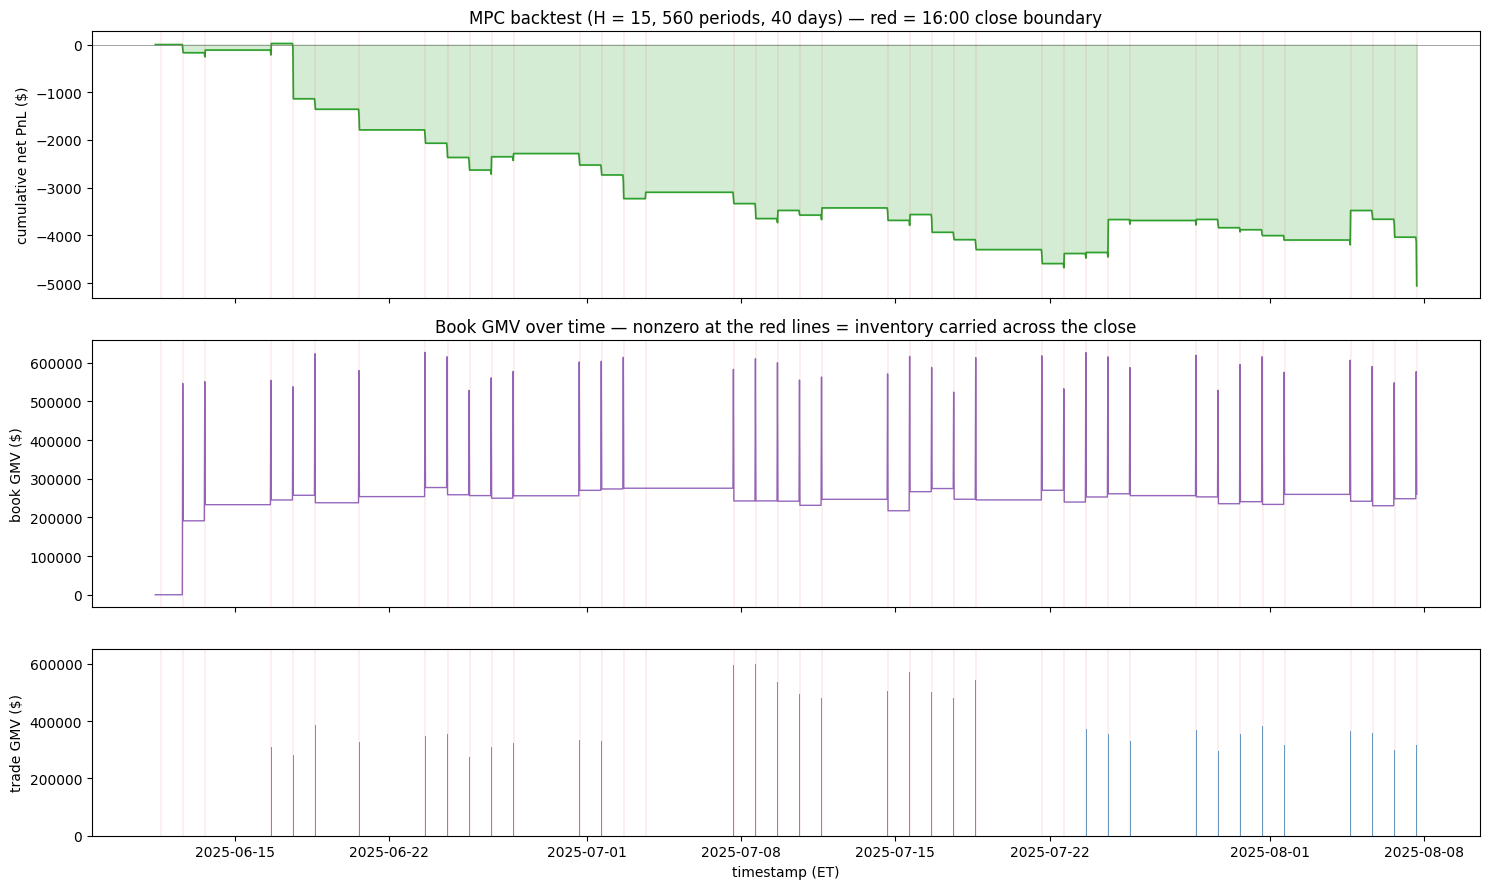

In [19]:

dts   = results["start_ts"].to_list()
cnet  = results["cum_net_pnl"].to_numpy()
gmv   = results["book_gmv"].to_numpy()
tgmv  = results["trade_gmv"].to_numpy()
close_ts = results.filter(pl.col("kind") == "overnight")["start_ts"].to_list()

fig, (ax_pnl, ax_gmv, ax_trade) = plt.subplots(3, 1, figsize=(15, 9), sharex=True,
                                               height_ratios=[1, 1, 0.7])

ax_pnl.plot(dts, cnet, color="tab:green", lw=1.2)
ax_pnl.fill_between(dts, cnet, color="tab:green", alpha=0.2)
ax_pnl.axhline(0, color="grey", lw=0.5)
for ct in close_ts:
    ax_pnl.axvline(ct, color="tab:red", lw=0.3, alpha=0.35)
ax_pnl.set_ylabel("cumulative net PnL ($)")
ax_pnl.set_title(
    f"MPC backtest (H = {HORIZON}, {len(results)} periods, "
    f"{len(set(results['date'].to_list()))} days) — red = 16:00 close boundary"
)

ax_gmv.plot(dts, gmv, color="tab:purple", lw=1.0)
for ct in close_ts:
    ax_gmv.axvline(ct, color="tab:red", lw=0.3, alpha=0.35)
ax_gmv.set_ylabel("book GMV ($)")
ax_gmv.set_title("Book GMV over time — nonzero at the red lines = inventory carried across the close")

ax_trade.bar(dts, tgmv, color="tab:blue", alpha=0.7, width=0.02)
for ct in close_ts:
    ax_trade.axvline(ct, color="tab:red", lw=0.3, alpha=0.35)
ax_trade.set_ylabel("trade GMV ($)")
ax_trade.set_xlabel("timestamp (ET)")

fig.tight_layout()
plt.show()


In [20]:

# --- Numeric sanity: does GMV actually carry across the close? ----------
overnight_rows = results.filter(pl.col("kind") == "overnight")
n_carrying     = int((overnight_rows["book_gmv"] > 1.0).sum())
n_overnight    = overnight_rows.height
print(f"Overnight periods with GMV > $1: {n_carrying} / {n_overnight}  "
      f"({(n_carrying / max(n_overnight, 1)):.0%})")
print(f"Mean GMV during overnight:       ${overnight_rows['book_gmv'].mean():,.1f}")
print(f"Mean intraday GMV:               ${results.filter(pl.col('kind') == 'intraday')['book_gmv'].mean():,.1f}")
print()
print("Aggregates over the backtest:")
print(f"  Total gross PnL:  ${results['gross_pnl'].sum():+,.2f}")
print(f"  Total spread:     ${results['spread_cost'].sum():+,.2f}")
print(f"  Total impact:     ${results['impact_cost'].sum():+,.2f}")
print(f"  Total net PnL:    ${results['net_pnl'].sum():+,.2f}")


Overnight periods with GMV > $1: 39 / 40  (98%)
Mean GMV during overnight:       $243,827.2
Mean intraday GMV:               $262,278.0

Aggregates over the backtest:
  Total gross PnL:  $+339.69
  Total spread:     $+5,396.30
  Total impact:     $+0.00
  Total net PnL:    $-5,056.61



## Summary and next steps

### What this scaffold shows

- The MPC QP compiles once and re-solves quickly (`cp.CLARABEL`, warm-started) at each of the
  ~500+ period ticks over the backtest window.
- Inventory is **carried across the close** (see GMV plot: the red 16:00 lines do not force
  GMV to zero). This is the key qualitative difference vs. `optimal_portfolio.ipynb`.
- Alphas enter the horizon over time: at 15:30 on day *d* the close-auction alpha spike
  appears at horizon slot `tau=0` and the solve trades against it; earlier in the day the
  solve sees zero alpha in the horizon (as designed by the reveal rule).

### Deliberate simplifications (each flagged inline)

1. **Per-period covariance** $\Sigma_\tau$ — uniform intraday split + fixed overnight
   multiplier. Real work: intraday U-shape in variance, dedicated overnight-gap covariance.
2. **`sigma_i` in the impact coefficient** stays at the causal EWMA DAILY return-vol; only the
   per-bucket $-volume `PV$_{i,b,d}` is per-period. A per-period causal vol would be a fuller
   U-shape — noted for future refinement.
3. **Terminal cost-to-go** $\Phi_\text{terminal}$ — terminal risk + notional 3/2-power
   liquidation impact. Real work: Gârleanu–Pedersen value function derived from discounted
   alpha decay and impact.
4. **Single alpha (close-auction only)** with a 15:30 reveal-time simplification. Real work:
   `AlphaAggregator` term-structure layer that stacks multiple alphas (intraday, close,
   overnight) with per-alpha decay kernels.
5. **Spread cost** — per-name sample-mean quoted spread, held constant across periods. Real
   work: time-of-day-varying spread (open/close widening).
6. **Impact is temporary only** (no permanent-impact term).
7. **`N_DAYS_BACKTEST = 40`** — contiguous subset so nbconvert stays fast. Set to `None` for
   the full ~250-day sequential run.
8. **Universe / risk model / impact are fixed** for the whole sample (no walk-forward).
